<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/9_2_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
%%writefile main.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <sys/stat.h>

long long dosyaBoyutunuAl(const std::string& dosyaAdi) {
    struct stat statBuf;
    if (stat(dosyaAdi.c_str(), &statBuf) == 0) {
        return statBuf.st_size;
    }
    return -1;
}

int main() {
    std::string renkliDosya = "renkli_1000x1000.bmp";

    // 1000x1000, 3 kanallı matris oluştur ve kaydet
    cv::Mat renkliImg(1000, 1000, CV_8UC3, cv::Scalar(150, 100, 50));
    cv::imwrite(renkliDosya, renkliImg);

    // Gri tonlu resme dönüştür ve kaydet
    cv::Mat griImg;
    cv::cvtColor(renkliImg, griImg, cv::COLOR_BGR2GRAY);
    std::string griDosya = "gri_1000x1000.bmp";
    cv::imwrite(griDosya, griImg);

    // Boyutları yazdır
    long long boyutRenkli = dosyaBoyutunuAl(renkliDosya);
    long long boyutGri = dosyaBoyutunuAl(griDosya);

    std::cout << "Renkli BMP Boyutu : " << boyutRenkli << " bayt\n";
    std::cout << "Gri Seviye BMP Boyutu: " << boyutGri << " bayt\n";

    return 0;
}

Overwriting main.cpp


In [12]:
!g++ main.cpp -o main `pkg-config --cflags --libs opencv4`
!./main

Package opencv4 was not found in the pkg-config search path.
Perhaps you should add the directory containing `opencv4.pc'
to the PKG_CONFIG_PATH environment variable
Package 'opencv4', required by 'virtual:world', not found
main.cpp:1:10: fatal error: opencv2/opencv.hpp: No such file or directory
    1 | #include <opencv2/opencv.hpp>
      |          ^~~~~~~~~~~~~~~~~~~~
compilation terminated.
/bin/bash: line 1: ./main: No such file or directory


--- Renkli Bitmap Resmi ---


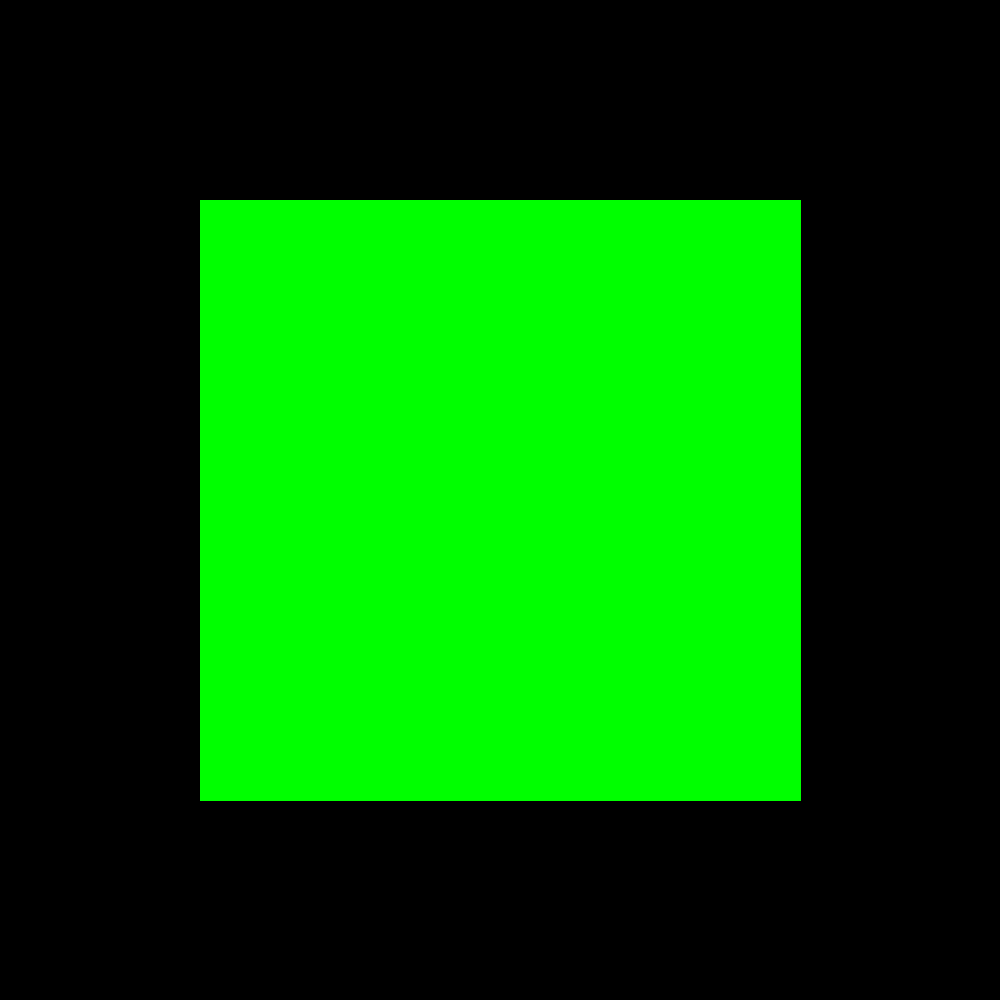

--- Gri Tonlu Bitmap Resmi ---


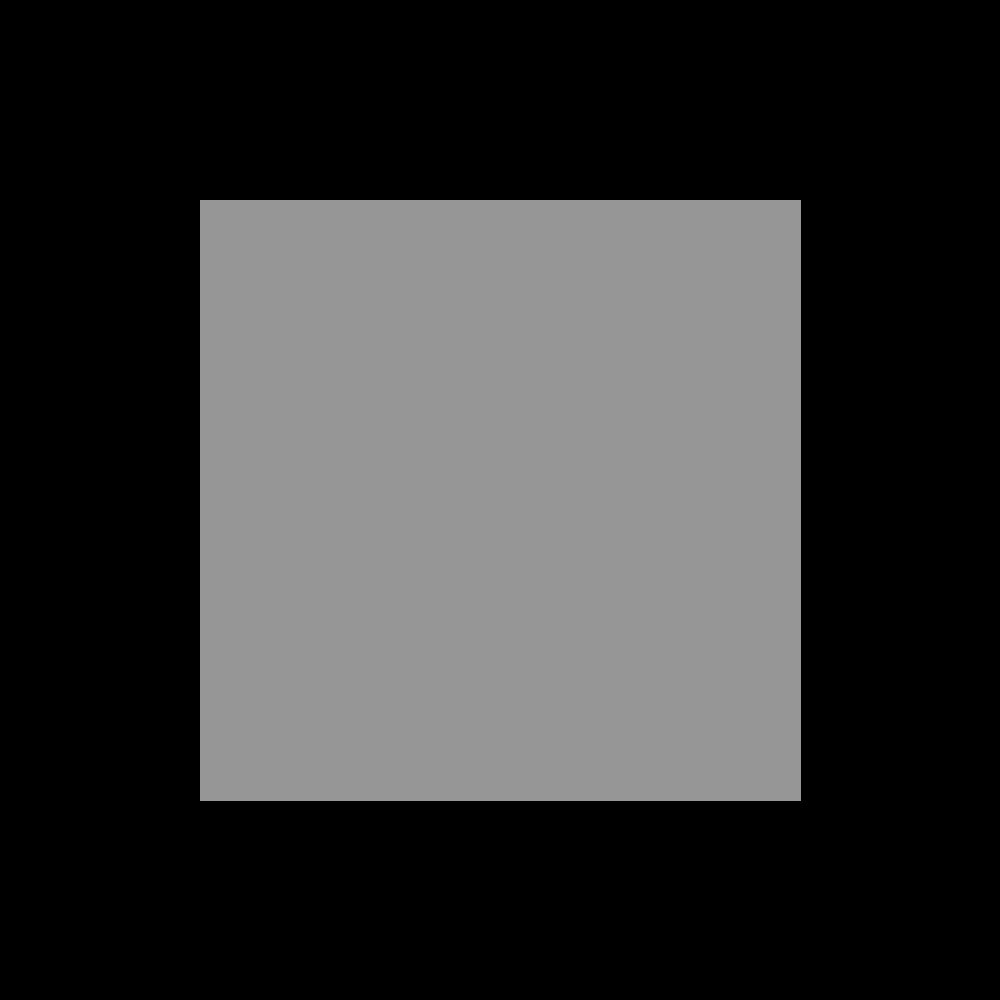

In [13]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow # Colab için görsel gösterme kütüphanesi

# 1. 1000x1000 renkli BMP resmi oluşturalım ve kaydedelim
dosya_adi_renkli = "renkli_1000x1000.bmp"
renkli_img = np.zeros((1000, 1000, 3), dtype=np.uint8)
# Üzerinde renkli şekiller olsun ki görsel olduğu anlaşılsın
cv2.rectangle(renkli_img, (200, 200), (800, 800), (0, 255, 0), -1) # Yeşil kare
cv2.imwrite(dosya_adi_renkli, renkli_img)

# 2. Resmi okuyup ekranda gösterelim
print("--- Renkli Bitmap Resmi ---")
okunan_renkli = cv2.imread(dosya_adi_renkli)
cv2_imshow(okunan_renkli)

# 3. Gri tonluya dönüştürüp kaydedelim
gri_img = cv2.cvtColor(okunan_renkli, cv2.COLOR_BGR2GRAY)
dosya_adi_gri = "gri_1000x1000.bmp"
cv2.imwrite(dosya_adi_gri, gri_img)

# 4. Gri resmi ekranda gösterelim
print("--- Gri Tonlu Bitmap Resmi ---")
okunan_gri = cv2.imread(dosya_adi_gri)
cv2_imshow(okunan_gri)